# Optimizer 1: Gradient Descent (constant learning rate, L1 penalty)

Same settings as the original `Gradient_Descent` cell, with `SGDRegressor` replaced by `SGDClassifier(loss='log_loss')`.

**Task:** predict whether a person earns more than 50K (`adult-training.csv`). Put the CSV in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, classification_report)

In [2]:
cols = ['age','workclass','fnlwgt','education','education_num','marital_status','occupation',
        'relationship','race','sex','capital_gain','capital_loss','hours_per_week','native_country','income']
data = pd.read_csv('adult-training.csv', header=None, names=cols, skipinitialspace=True, na_values='?')
print(data.shape)
data.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# Missing values (marked '?' in the file) -> fill with the mode, same as the original notebook
for col in ['workclass', 'occupation', 'native_country']:
    data[col] = data[col].fillna(data[col].mode()[0])

# education_num already encodes education as an ordered number -> drop the text column
data = data.drop(columns=['education'])

# Binary columns -> 0/1
data['sex'] = data['sex'].map({'Female': 0, 'Male': 1})
data['income'] = data['income'].map({'<=50K': 0, '>50K': 1})   # target: 1 = earns more than 50K

# Remaining categorical columns -> one-hot
data = pd.get_dummies(data, drop_first=True)

x = data.drop('income', axis=1)
y = data['income']
print('Positive class rate:', round(y.mean(), 3))

Positive class rate: 0.241


In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, train_size=0.8, random_state=42, stratify=y)

ForScaling = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
scaler = StandardScaler()
x_train_Scaled = x_train.copy()
x_test_Scaled = x_test.copy()
x_train_Scaled[ForScaling] = scaler.fit_transform(x_train[ForScaling])
x_test_Scaled[ForScaling] = scaler.transform(x_test[ForScaling])
x_train_Scaled = x_train_Scaled.astype(float)
x_test_Scaled = x_test_Scaled.astype(float)
x_train_Scaled.shape, x_test_Scaled.shape

((26048, 82), (6513, 82))

In [5]:
def evaluate(y_true, y_pred, y_proba, name):
    print(f'=== {name} ===')
    print(f'Accuracy : {accuracy_score(y_true, y_pred):.4f}')
    print(f'Precision: {precision_score(y_true, y_pred):.4f}')
    print(f'Recall   : {recall_score(y_true, y_pred):.4f}')
    print(f'F1       : {f1_score(y_true, y_pred):.4f}')
    print(f'ROC-AUC  : {roc_auc_score(y_true, y_proba):.4f}')
    print(f'Log loss : {log_loss(y_true, y_proba):.4f}')
    print()
    print(classification_report(y_true, y_pred, target_names=['<=50K', '>50K']))
    sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
                xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(name); plt.show()

In [6]:
from sklearn.linear_model import SGDClassifier
NAME = 'Gradient Descent (constant lr, L1)'
model = SGDClassifier(
    loss='log_loss',
    max_iter=2000,
    penalty='l1',
    learning_rate='constant',
    eta0=0.01,
    random_state=42
)
model.fit(x_train_Scaled, y_train)

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l1'
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",2000
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"learning_rate learning_rate: str, default='optimal'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where `t0` is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': `eta = eta0`, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if `early_stopping` is `True`, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='hinge'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='hinge'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'constant'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`pe

=== Gradient Descent (constant lr, L1) ===
Accuracy : 0.8541
Precision: 0.7696
Recall   : 0.5625
F1       : 0.6500
ROC-AUC  : 0.9072
Log loss : 0.3187

              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.91      4945
        >50K       0.77      0.56      0.65      1568

    accuracy                           0.85      6513
   macro avg       0.82      0.75      0.78      6513
weighted avg       0.85      0.85      0.85      6513



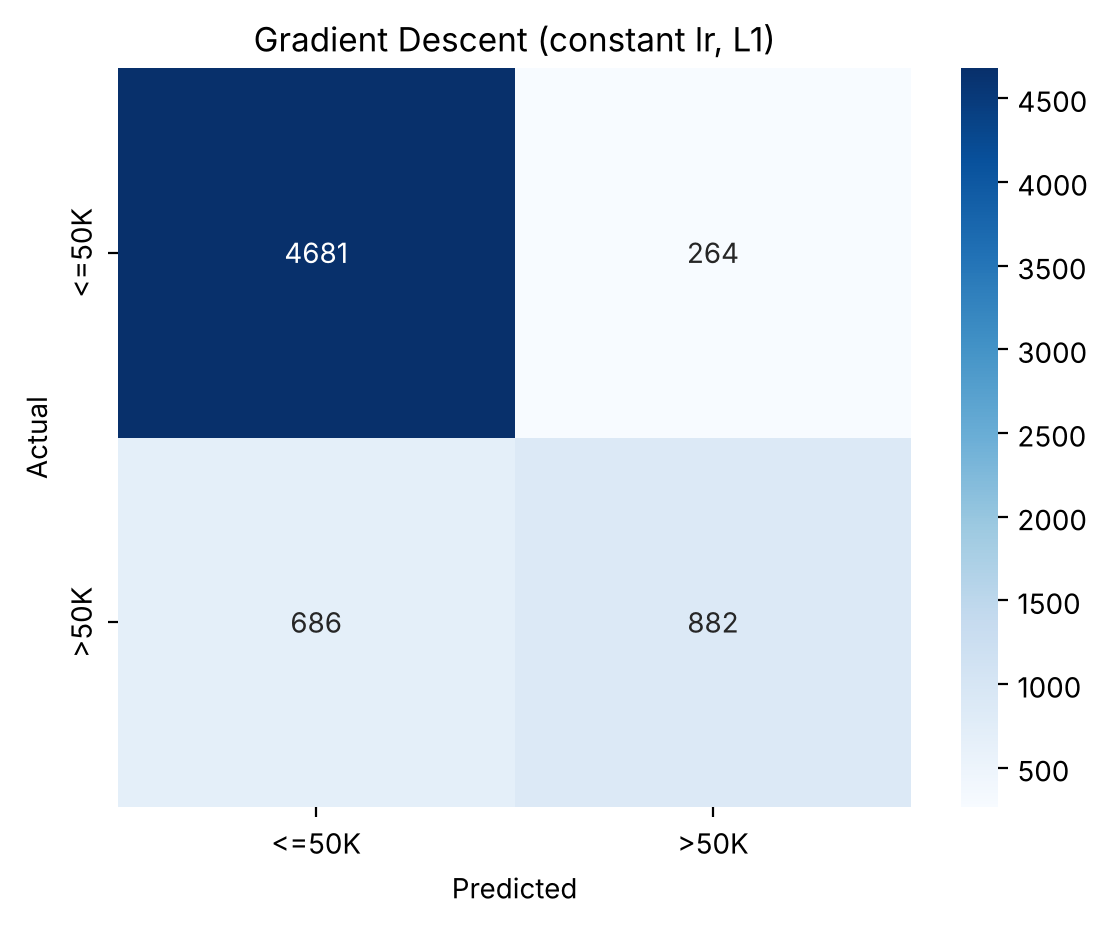

In [7]:
y_proba = model.predict_proba(x_test_Scaled)[:, 1]
y_pred = model.predict(x_test_Scaled)
evaluate(y_test, y_pred, y_proba, NAME)